# 01. Análisis exploratorio (Credit Risk Analysis)

**Contexto.** Una entidad financiera necesita anticipar qué clientes tienen mayor probabilidad de caer en
mora grave (90 días o más de atraso) durante los próximos dos años. El dataset *Give Me Some Credit*
(Kaggle, 2011) contiene 150 000 clientes con historial de crédito y la etiqueta observada
`SeriousDlqin2yrs`.

**Objetivo del notebook.**
1. Entender la calidad de los datos (nulos, valores imposibles, códigos especiales, extremos).
2. Identificar qué variables se asocian con la mora.
3. Justificar las reglas de limpieza que luego usa el modelo (`src/limpieza.py`).

Solo se usa `cs-training.csv` (el único archivo con etiqueta). Todas las cifras que aparecen en el texto
se calculan en las celdas de este notebook.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import hashlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.cargar_datos import (COLUMNAS_ATRASO, OBJETIVO, PREDICTORAS_ORIGINALES, RUTA_TRAINING,
                              cargar_datos, cargar_diccionario, detectar_problemas,
                              resumen_calidad, validar_objetivo)
from src.limpieza import (PREDICTORAS_MODELO, aplicar_reglas_limpieza, rango_atrasos, rango_edad,
                          tramo_utilizacion)
from src.graficos import (AZUL, AZUL_CLARO, NARANJA, TINTA, TINTA_SECUNDARIA, aplicar_estilo,
                          etiquetar_barras, guardar_figura)

aplicar_estilo()
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", "{:,.4f}".format)

hash_inicial = hashlib.sha256(RUTA_TRAINING.read_bytes()).hexdigest()
print("SHA-256 de cs-training.csv:", hash_inicial)

SHA-256 de cs-training.csv: 1bd46da486a5708c58c7b01a034fae2a13b327f6f7b62ea7ba4fe3b5824b24ac


## 1. Diccionario de variables

In [2]:
diccionario = cargar_diccionario()
diccionario

,variable,descripcion,tipo
0,SeriousDlqin2yrs,Person experienced 90 days past due delinquency or worse,Y/N
1,RevolvingUtilizationOfUnsecuredLines,Total balance on credit cards and personal lines of credit except real estate and no installment debt like car loans...,percentage
2,age,Age of borrower in years,integer
3,NumberOfTime30-59DaysPastDueNotWorse,Number of times borrower has been 30-59 days past due but no worse in the last 2 years.,integer
4,DebtRatio,"Monthly debt payments, alimony,living costs divided by monthy gross income",percentage
5,MonthlyIncome,Monthly income,real
6,NumberOfOpenCreditLinesAndLoans,Number of Open loans (installment like car loan or mortgage) and Lines of credit (e.g. credit cards),integer
7,NumberOfTimes90DaysLate,Number of times borrower has been 90 days or more past due.,integer
8,NumberRealEstateLoansOrLines,Number of mortgage and real estate loans including home equity lines of credit,integer
9,NumberOfTime60-89DaysPastDueNotWorse,Number of times borrower has been 60-89 days past due but no worse in the last 2 years.,integer


El diccionario oficial **no documenta** los valores 96 y 98 de las variables de atraso ni explica qué
ocurre con `DebtRatio` cuando falta el ingreso. Ambas situaciones se analizan con los datos en las
secciones 5 y 6.

## 2. Carga de datos y exploración inicial

In [3]:
df = cargar_datos()
validar_objetivo(df)
print(f"Dimensiones: {df.shape[0]:,} filas x {df.shape[1]} columnas")
print(f"Identificadores duplicados: {df.index.duplicated().sum()}")
df.head()

Dimensiones: 150,000 filas x 11 columnas
Identificadores duplicados: 0


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
id_cliente,,,,,,,,,,,
1,1,0.7661,45,2,0.8030,"9,120.0000",13,0,6,0,2.0000
2,0,0.9572,40,0,0.1219,"2,600.0000",4,0,0,0,1.0000
3,0,0.6582,38,1,0.0851,"3,042.0000",2,1,0,0,0.0000
4,0,0.2338,30,0,0.0360,"3,300.0000",5,0,0,0,0.0000
5,0,0.9072,49,1,0.0249,"63,588.0000",7,0,1,0,0.0000


In [4]:
resumen_calidad(df)

,tipo,nulos,pct_nulos,valores_unicos,minimo,mediana,p99,maximo
columna,,,,,,,,
SeriousDlqin2yrs,int64,0,0.0000,2,0.0000,0.0000,1.0000,1.0000
RevolvingUtilizationOfUnsecuredLines,float64,0,0.0000,125728,0.0000,0.1542,1.0930,"50,708.0000"
age,int64,0,0.0000,86,0.0000,52.0000,87.0000,109.0000
NumberOfTime30-59DaysPastDueNotWorse,int64,0,0.0000,16,0.0000,0.0000,4.0000,98.0000
DebtRatio,float64,0,0.0000,114194,0.0000,0.3665,"4,979.0400","329,664.0000"
MonthlyIncome,float64,29731,19.8200,13594,0.0000,"5,400.0000","25,000.0000","3,008,750.0000"
NumberOfOpenCreditLinesAndLoans,int64,0,0.0000,58,0.0000,8.0000,24.0000,58.0000
NumberOfTimes90DaysLate,int64,0,0.0000,19,0.0000,0.0000,3.0000,98.0000
NumberRealEstateLoansOrLines,int64,0,0.0000,28,0.0000,1.0000,4.0000,54.0000


In [5]:
problemas = pd.Series(detectar_problemas(df), name="filas")
problemas.to_frame()

,filas
filas,150000
columnas,11
ids_duplicados,0
filas_duplicadas_sin_id,609
MonthlyIncome_nulo,29731
NumberOfDependents_nulo,3924
age_menor_18,1
age_igual_0,1
atraso_codigo_96_98,269
utilizacion_mayor_1,3321


Todas las columnas son numéricas. Los problemas a tratar son: ingresos y dependientes nulos, una edad
imposible, 269 clientes con códigos 96/98, utilizaciones de crédito extremas y un `DebtRatio` muy alto
concentrado en clientes sin ingreso informado. Hay 609 filas idénticas a otra (sin contar el id).

## 3. Variable objetivo

                  clientes  porcentaje
SeriousDlqin2yrs                      
0                   139974     93.3200
1                    10026      6.6800


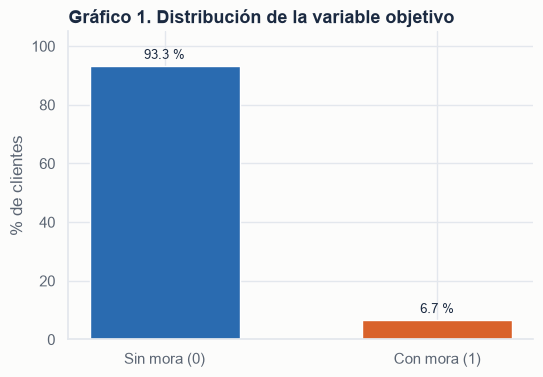

In [6]:
conteo = df[OBJETIVO].value_counts().sort_index()
proporcion = df[OBJETIVO].value_counts(normalize=True).sort_index() * 100
print(pd.DataFrame({"clientes": conteo, "porcentaje": proporcion.round(2)}))

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["Sin mora (0)", "Con mora (1)"], proporcion.values, color=[AZUL, NARANJA], width=0.55)
etiquetar_barras(ax)
ax.set_ylabel("% de clientes")
ax.set_ylim(0, 105)
ax.set_title("Gráfico 1. Distribución de la variable objetivo")
guardar_figura(fig, "01_distribucion_objetivo")
plt.show()

**Interpretación.** 10 026 de 150 000 clientes (6,68 %) presentaron mora grave. El problema está
fuertemente desbalanceado: un modelo que dijera siempre "sin mora" acertaría el 93,32 % de las veces
sin detectar ni un solo incumplimiento. Por eso la evaluación del modelo se basará en ROC-AUC, recall y
precision de la clase positiva, no en accuracy.

## 4. Valores faltantes

MonthlyIncome         29731
NumberOfDependents     3924
dtype: int64
Clientes con dependientes nulos que también tienen ingreso nulo: 3924


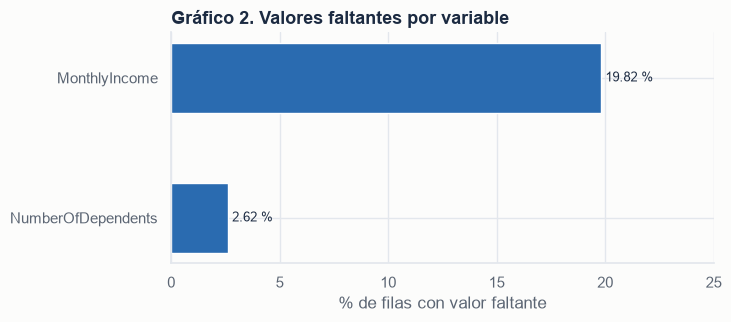

In [7]:
nulos = (df.isna().mean() * 100).sort_values()
nulos = nulos[nulos > 0]
print(df.isna().sum()[df.isna().sum() > 0])
print("Clientes con dependientes nulos que también tienen ingreso nulo:",
      (df["NumberOfDependents"].isna() & df["MonthlyIncome"].isna()).sum())

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(nulos.index, nulos.values, color=AZUL, height=0.5)
etiquetar_barras(ax, formato="{:.2f} %")
ax.set_xlabel("% de filas con valor faltante")
ax.set_xlim(0, 25)
ax.set_title("Gráfico 2. Valores faltantes por variable")
guardar_figura(fig, "02_valores_faltantes")
plt.show()

In [8]:
pd.DataFrame({
    "tasa_mora_ingreso_faltante_%": df.groupby(df["MonthlyIncome"].isna())[OBJETIVO].mean() * 100,
    "tasa_mora_dependientes_faltante_%": df.groupby(df["NumberOfDependents"].isna())[OBJETIVO].mean() * 100,
}).rename(index={False: "informado", True: "faltante"}).round(2)

,tasa_mora_ingreso_faltante_%,tasa_mora_dependientes_faltante_%
informado,6.9500,6.7400
faltante,5.6100,4.5600


**Interpretación.** Solo dos variables tienen nulos: `MonthlyIncome` (29 731 filas, 19,82 %) y
`NumberOfDependents` (3 924 filas, 2,62 %). Los 3 924 clientes sin dependientes informados también
carecen de ingreso, lo que sugiere un mismo origen (formularios incompletos). La ausencia **no es
aleatoria respecto a la mora**: los clientes sin ingreso tienen una tasa de 5,61 % frente a 6,95 % de
quienes lo informan. Eliminar esas filas descartaría el 20 % de la cartera y sesgaría la muestra; por eso
se imputa la mediana (ajustada solo con entrenamiento) **y** se conserva un indicador de ausencia.
La comparación cuantitativa entre ambas estrategias se hace en `02_modelo.ipynb`.

## 5. Edades inválidas

In [9]:
print("age < 18:", (df["age"] < 18).sum(), "| valores:", sorted(df.loc[df["age"] < 18, "age"].unique()))
print("age > 100:", (df["age"] > 100).sum(), "| máximo:", df["age"].max())
df["age"].describe()

age < 18: 1 | valores: [np.int64(0)]
age > 100: 13 | máximo: 109


count   150,000.0000
mean         52.2952
std          14.7719
min           0.0000
25%          41.0000
50%          52.0000
75%          63.0000
max         109.0000
Name: age, dtype: float64

Existe una única fila con `age = 0`, imposible para un titular de crédito: se convierte en nulo y se
imputa con la mediana. Las 13 personas mayores de 100 años (máximo 109) son poco frecuentes pero
plausibles, así que se conservan.

## 6. Valores extremos

In [10]:
extremos = df[PREDICTORAS_ORIGINALES].quantile([0.5, 0.99, 0.999]).T
extremos["maximo"] = df[PREDICTORAS_ORIGINALES].max()
extremos

,0.5000,0.9900,0.9990,maximo
RevolvingUtilizationOfUnsecuredLines,0.1542,1.0930,"1,571.0060","50,708.0000"
age,52.0000,87.0000,94.0000,109.0000
NumberOfTime30-59DaysPastDueNotWorse,0.0000,4.0000,98.0000,98.0000
DebtRatio,0.3665,"4,979.0400","10,613.0740","329,664.0000"
MonthlyIncome,"5,400.0000","25,000.0000","78,395.7480","3,008,750.0000"
NumberOfOpenCreditLinesAndLoans,8.0000,24.0000,34.0000,58.0000
NumberOfTimes90DaysLate,0.0000,3.0000,98.0000,98.0000
NumberRealEstateLoansOrLines,1.0000,4.0000,9.0000,54.0000
NumberOfTime60-89DaysPastDueNotWorse,0.0000,2.0000,98.0000,98.0000
NumberOfDependents,0.0000,4.0000,6.0000,20.0000


In [11]:
# DebtRatio se comporta como un monto absoluto cuando falta el ingreso
df.groupby(df["MonthlyIncome"].isna().map({False: "ingreso informado", True: "ingreso faltante"}))["DebtRatio"].describe()

,count,mean,std,min,25%,50%,75%,max
MonthlyIncome,,,,,,,,
ingreso faltante,"29,731.0000","1,673.3966","4,248.3729",0.0000,123.0000,"1,159.0000","2,382.0000","329,664.0000"
ingreso informado,"120,269.0000",26.5988,424.4465,0.0000,0.1434,0.2960,0.4826,"61,106.5000"


In [12]:
tramos_util = (df.assign(tramo=tramo_utilizacion(df["RevolvingUtilizationOfUnsecuredLines"]))
                 .groupby("tramo")[OBJETIVO].agg(clientes="size", tasa_mora="mean"))
tramos_util["tasa_mora"] *= 100
tramos_util.round(2)

,clientes,tasa_mora
tramo,,
30-60%,21887,6.6800
60-90%,15161,13.3000
90-100%,16749,19.4000
<30%,92882,2.2200
Extremo (>10),241,7.0500
Sobre límite (1-10),3080,39.6100


**Hallazgos sobre extremos.**

* `RevolvingUtilizationOfUnsecuredLines` es un cociente saldo/límite. 3 080 clientes están entre 1 y 10
  (sobre su límite) y tienen una mora de 39,6 %: es una señal real de estrés financiero y se conserva.
  En cambio, los 241 valores mayores que 10 (hasta 50 708) tienen una mora de 7,05 %, prácticamente igual
  a la media (6,68 %): no se comportan como clientes sobreendeudados y probablemente son errores de
  registro. Se convierten en nulo y se marca `utilizacion_extrema`.
* `DebtRatio` tiene mediana 0,30 cuando hay ingreso, pero 1 159 cuando el ingreso falta: en esas filas el
  valor parece ser la deuda mensual en términos absolutos, no un cociente. No se modifica, pero el
  indicador `ingreso_faltante` permite al modelo distinguir ambos casos.
* `MonthlyIncome` tiene 70 clientes con más de 100 000 al mes (máximo 3 008 750). Son poco comunes
  pero posibles; se conservan. Los promedios de ingreso se reportan también sin ellos en SQL.
* Conteos altos de líneas de crédito (máximo 58) o préstamos inmobiliarios (máximo 54) son raros pero
  no imposibles; se conservan.

## 7. Códigos especiales 96 y 98 en las variables de atraso

In [13]:
for columna in COLUMNAS_ATRASO:
    print(columna, df[columna].value_counts().sort_index().tail(5).to_dict())

especial = df[COLUMNAS_ATRASO].isin([96, 98])
print("\nFilas con 96/98 en alguna columna:", especial.any(axis=1).sum())
print("Filas con 96/98 en las tres columnas a la vez:", especial.all(axis=1).sum())
print("Tasa de mora de esas filas: {:.2%}".format(df.loc[especial.any(axis=1), OBJETIVO].mean()))

NumberOfTime30-59DaysPastDueNotWorse {11: 1, 12: 2, 13: 1, 96: 5, 98: 264}
NumberOfTime60-89DaysPastDueNotWorse {8: 2, 9: 1, 11: 1, 96: 5, 98: 264}
NumberOfTimes90DaysLate {14: 2, 15: 2, 17: 1, 96: 5, 98: 264}

Filas con 96/98 en alguna columna: 269
Filas con 96/98 en las tres columnas a la vez: 269
Tasa de mora de esas filas: 54.65%


Los conteos válidos llegan como máximo a 13 (30-59 días), 11 (60-89 días) y 17 (90+ días). Luego hay un
salto directo a 96 y 98, que aparecen **siempre en las tres columnas a la vez** (269 filas). En dos años no
es posible acumular 98 atrasos de 30-59 días, por lo que se interpretan como códigos especiales del sistema
de origen (p. ej. "dato no disponible" o "rechazado"), no como conteos.

Sin embargo, esos 269 clientes tienen una mora de 54,65 %, ocho veces la media. Eliminarlos o
reemplazarlos por cero ocultaría una señal muy fuerte. Decisión: reemplazar 96/98 por nulo (imputación
con mediana dentro del pipeline) y crear el indicador `codigo_especial_atraso`.

## 8. Aplicación de las reglas de limpieza

In [14]:
df_limpio, registro = aplicar_reglas_limpieza(df)
registro

,regla,columna,accion,filas_afectadas
0,ingreso_nulo,MonthlyIncome,indicador ingreso_faltante; imputar mediana en pipeline,29731
1,dependientes_nulo,NumberOfDependents,indicador dependientes_faltante; imputar mediana en pipeline,3924
2,edad_invalida,age,age < 18 -> NaN; imputar mediana en pipeline,1
3,codigo_especial_atraso,"NumberOfTime30-59DaysPastDueNotWorse, NumberOfTime60-89DaysPastDueNotWorse, NumberOfTimes90DaysLate",96/98 -> NaN + indicador codigo_especial_atraso,269
4,utilizacion_extrema,RevolvingUtilizationOfUnsecuredLines,> 10 -> NaN + indicador utilizacion_extrema,241
5,filas_duplicadas,todas,se conservan (sin identificador de persona),609


In [15]:
# El DataFrame original no se modifica: las reglas trabajan sobre una copia
assert df["age"].min() == 0 and df["NumberOfTimes90DaysLate"].max() == 98
assert df_limpio["age"].min() >= 18 and df_limpio[COLUMNAS_ATRASO].max().max() < 96
print("Original intacto; copia limpia con", df_limpio.shape[1], "columnas")

Original intacto; copia limpia con 15 columnas


## 9. Distribuciones de las variables numéricas

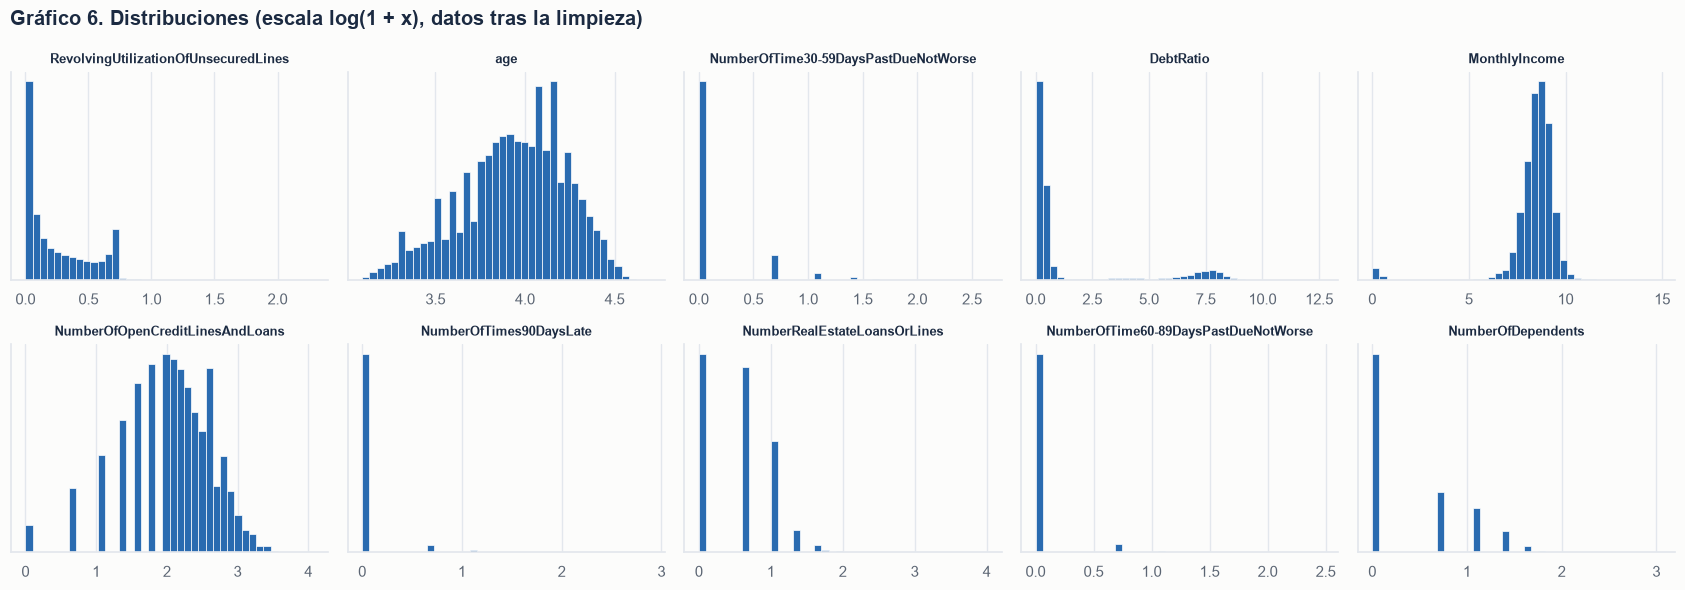

In [16]:
fig, ejes = plt.subplots(2, 5, figsize=(17, 6))
for ax, columna in zip(ejes.ravel(), PREDICTORAS_ORIGINALES):
    valores = df_limpio[columna].dropna()
    ax.hist(np.log1p(valores), bins=40, color=AZUL, edgecolor="white", linewidth=0.5)
    ax.set_title(columna, fontsize=9, loc="center")
    ax.set_yticks([])
fig.suptitle("Gráfico 6. Distribuciones (escala log(1 + x), datos tras la limpieza)",
             x=0.01, ha="left", fontweight="bold", color=TINTA)
fig.tight_layout()
guardar_figura(fig, "06_distribuciones")
plt.show()

**Interpretación.** Casi todas las variables son muy asimétricas a la derecha (ingreso, ratio de deuda,
utilización) o están concentradas en cero (los tres conteos de atraso: entre 84,0 % y 94,9 % de clientes sin
atrasos). La edad es la única aproximadamente simétrica. Esto justifica usar la transformación
`log1p` y estandarizar antes de la regresión logística; Random Forest no la necesita.

## 10. Análisis bivariado: variables predictoras y mora

            clientes  tasa_mora
rango_edad                     
18-29           8820    11.7300
30-44          38982     9.4900
45-59          53879     7.0400
60+            48318     3.1000


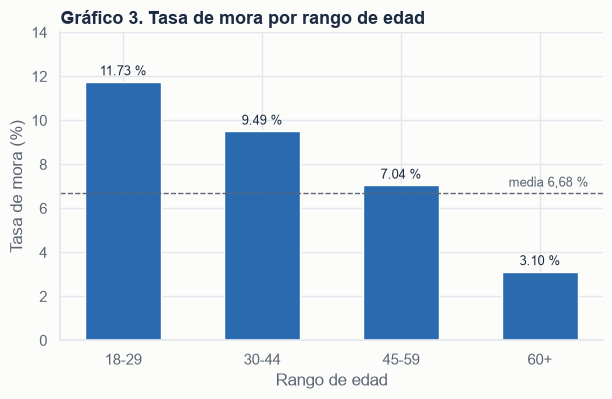

In [17]:
por_edad = (df.assign(rango_edad=rango_edad(df["age"]))
              .query("rango_edad != 'Edad inválida'")
              .groupby("rango_edad")[OBJETIVO].agg(clientes="size", tasa_mora="mean"))
por_edad["tasa_mora"] *= 100
print(por_edad.round(2))

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(por_edad.index, por_edad["tasa_mora"], color=AZUL, width=0.55)
ax.axhline(df[OBJETIVO].mean() * 100, color=TINTA_SECUNDARIA, linestyle="--", linewidth=1)
ax.text(3.35, df[OBJETIVO].mean() * 100 + 0.3, "media 6,68 %", color=TINTA_SECUNDARIA, fontsize=9, ha="right")
etiquetar_barras(ax, formato="{:.2f} %")
ax.set_xlabel("Rango de edad")
ax.set_ylabel("Tasa de mora (%)")
ax.set_ylim(0, 14)
ax.set_title("Gráfico 3. Tasa de mora por rango de edad")
guardar_figura(fig, "03_mora_por_edad")
plt.show()

**Interpretación.** La mora disminuye de forma monótona con la edad: 11,73 % entre 18 y 29 años,
9,49 % entre 30 y 44, 7,04 % entre 45 y 59 y 3,10 % a partir de 60. Los menores de 30 tienen casi cuatro
veces la tasa de los mayores de 60. La edad es una asociación, no una causa: probablemente refleja
diferencias en estabilidad laboral, patrimonio e historial crediticio.

             30-59 días           60-89 días           90 días o más          
               clientes tasa_mora   clientes tasa_mora      clientes tasa_mora
0                126018    4.0000     142396    5.1000        141662    4.6300
1                 16033   15.0300       5731   31.0100          5243   33.6600
2                  4598   26.5100       1118   50.1800          1555   49.9000
3                  1754   35.2300        318   56.6000           667   57.7200
4+                 1328   44.5800        168   62.5000           604   66.0600
Código 96/98        269   54.6500        269   54.6500           269   54.6500


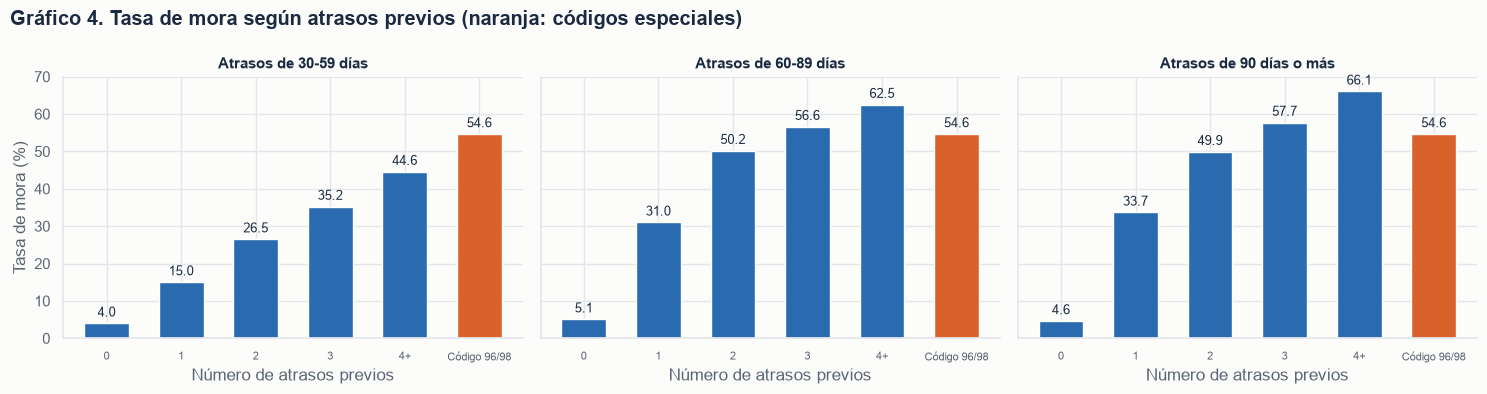

In [18]:
nombres_atraso = {"NumberOfTime30-59DaysPastDueNotWorse": "30-59 días",
                  "NumberOfTime60-89DaysPastDueNotWorse": "60-89 días",
                  "NumberOfTimes90DaysLate": "90 días o más"}
orden = ["0", "1", "2", "3", "4+", "Código 96/98"]
tablas = {}
for columna, nombre in nombres_atraso.items():
    tabla = df.groupby(rango_atrasos(df[columna]))[OBJETIVO].agg(clientes="size", tasa_mora="mean")
    tabla["tasa_mora"] *= 100
    tablas[nombre] = tabla.reindex(orden)
print(pd.concat(tablas, axis=1).round(2))

fig, ejes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (nombre, tabla) in zip(ejes, tablas.items()):
    colores = [NARANJA if i == "Código 96/98" else AZUL for i in tabla.index]
    ax.bar(tabla.index, tabla["tasa_mora"], color=colores, width=0.6)
    etiquetar_barras(ax, formato="{:.1f}")
    ax.set_title(f"Atrasos de {nombre}", fontsize=11, loc="center")
    ax.set_xlabel("Número de atrasos previos")
    ax.tick_params(axis="x", labelsize=8)
ejes[0].set_ylabel("Tasa de mora (%)")
ejes[0].set_ylim(0, 70)
fig.suptitle("Gráfico 4. Tasa de mora según atrasos previos (naranja: códigos especiales)",
             x=0.01, ha="left", fontweight="bold", color=TINTA)
fig.tight_layout()
guardar_figura(fig, "04_mora_por_atrasos")
plt.show()

**Interpretación.** El historial de atrasos es el factor más asociado con la mora futura. Sin atrasos de
30-59 días la tasa es 4,00 %; con uno sube a 15,03 % y con cuatro o más a 44,58 %. El patrón es aún más
fuerte en atrasos más graves: un solo episodio de 90 días o más eleva la tasa a 33,66 % y dos o más a
55,20 %. Los clientes con código 96/98 (54,65 %) se parecen a los peores perfiles, lo que confirma la
decisión de conservarlos con un indicador.

Mediana de utilización por estado:
SeriousDlqin2yrs
0   0.1330
1   0.8380
Name: RevolvingUtilizationOfUnsecuredLines, dtype: float64


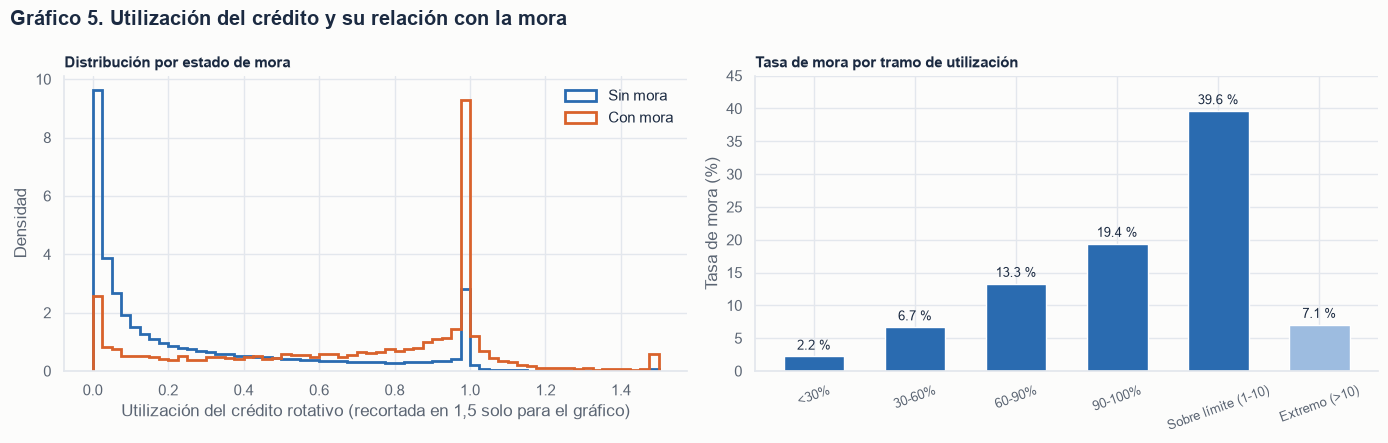

In [19]:
util = df_limpio["RevolvingUtilizationOfUnsecuredLines"]
print("Mediana de utilización por estado:")
print(df_limpio.groupby(OBJETIVO)["RevolvingUtilizationOfUnsecuredLines"].median().round(3))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
bins = np.linspace(0, 1.5, 61)
for valor, color, etiqueta in [(0, AZUL, "Sin mora"), (1, NARANJA, "Con mora")]:
    ax1.hist(util[df_limpio[OBJETIVO] == valor].clip(upper=1.5), bins=bins, density=True,
             histtype="step", linewidth=2, color=color, label=etiqueta)
ax1.set_xlabel("Utilización del crédito rotativo (recortada en 1,5 solo para el gráfico)")
ax1.set_ylabel("Densidad")
ax1.legend()
ax1.set_title("Distribución por estado de mora", fontsize=11)

orden_tramos = ["<30%", "30-60%", "60-90%", "90-100%", "Sobre límite (1-10)", "Extremo (>10)"]
tasa_tramo = tramos_util.reindex(orden_tramos)["tasa_mora"]
colores = [AZUL_CLARO if t == "Extremo (>10)" else AZUL for t in orden_tramos]
ax2.bar(range(len(orden_tramos)), tasa_tramo.values, color=colores, width=0.6)
ax2.set_xticks(range(len(orden_tramos)), orden_tramos, rotation=20, fontsize=9)
etiquetar_barras(ax2, formato="{:.1f} %")
ax2.set_ylabel("Tasa de mora (%)")
ax2.set_ylim(0, 45)
ax2.set_title("Tasa de mora por tramo de utilización", fontsize=11)
fig.suptitle("Gráfico 5. Utilización del crédito y su relación con la mora",
             x=0.01, ha="left", fontweight="bold", color=TINTA)
fig.tight_layout()
guardar_figura(fig, "05_utilizacion_credito")
plt.show()

**Interpretación.** Los clientes sin mora se concentran en utilizaciones bajas (mediana 0,133), mientras
que los clientes con mora se acumulan cerca o por encima del 100 % (mediana 0,838). La tasa de mora sube
de 2,22 % en el tramo inferior al 30 % hasta 19,40 % entre 90 y 100 % y 39,61 % sobre el límite. El tramo
extremo (> 10, en azul claro) rompe la tendencia con 7,05 %, lo que respalda tratarlo como error de
registro y no como sobreendeudamiento.

Mora por cuartil de ingreso (%):
 MonthlyIncome
(-0.001, 3400.0]      9.2100
(3400.0, 5400.0]      7.8700
(5400.0, 8249.0]      6.0700
(8249.0, 3008750.0]   4.6200
Name: SeriousDlqin2yrs, dtype: float64

Mora por dependientes (%):
 NumberOfDependents
Sin dato    4.5600
0           5.8600
1           7.3500
2           8.1100
3           8.8300
4+         10.2800
Name: SeriousDlqin2yrs, dtype: float64


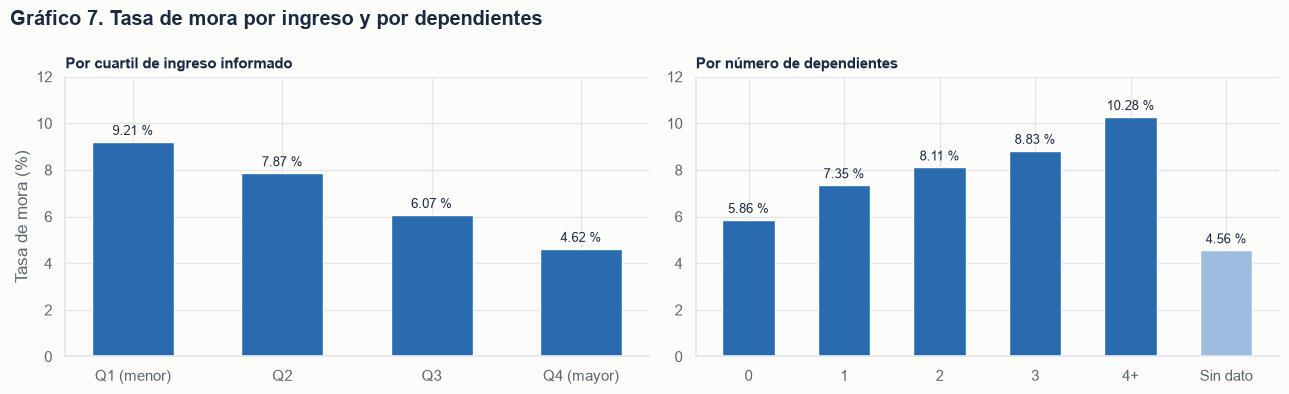

In [20]:
cuartiles = df.groupby(pd.qcut(df["MonthlyIncome"], 4))[OBJETIVO].mean() * 100
dependientes = df.groupby(df["NumberOfDependents"].clip(upper=4).fillna(-1))[OBJETIVO].mean() * 100
dependientes.index = dependientes.index.map({-1: "Sin dato", 0: "0", 1: "1", 2: "2", 3: "3", 4: "4+"})
print("Mora por cuartil de ingreso (%):\n", cuartiles.round(2))
print("\nMora por dependientes (%):\n", dependientes.round(2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.bar(["Q1 (menor)", "Q2", "Q3", "Q4 (mayor)"], cuartiles.values, color=AZUL, width=0.55)
etiquetar_barras(ax1, formato="{:.2f} %")
ax1.set_ylabel("Tasa de mora (%)")
ax1.set_ylim(0, 12)
ax1.set_title("Por cuartil de ingreso informado", fontsize=11)
orden_dep = ["0", "1", "2", "3", "4+", "Sin dato"]
ax2.bar(orden_dep, dependientes.reindex(orden_dep).values,
        color=[AZUL_CLARO if d == "Sin dato" else AZUL for d in orden_dep], width=0.55)
etiquetar_barras(ax2, formato="{:.2f} %")
ax2.set_ylim(0, 12)
ax2.set_title("Por número de dependientes", fontsize=11)
fig.suptitle("Gráfico 7. Tasa de mora por ingreso y por dependientes",
             x=0.01, ha="left", fontweight="bold", color=TINTA)
fig.tight_layout()
guardar_figura(fig, "07_mora_ingreso_dependientes")
plt.show()

**Interpretación.** A mayor ingreso, menor mora: 9,21 % en el cuartil inferior frente a 4,62 % en el
superior. Con los dependientes ocurre lo contrario: de 5,86 % sin dependientes a 10,28 % con cuatro o
más. Ambas relaciones son más suaves que las de atrasos o utilización.

## 11. Correlaciones

age                                    -0.1170
MonthlyIncome                          -0.0670
NumberOfOpenCreditLinesAndLoans        -0.0390
NumberRealEstateLoansOrLines           -0.0340
ingreso_faltante                       -0.0210
dependientes_faltante                  -0.0140
utilizacion_extrema                     0.0010
DebtRatio                               0.0210
NumberOfDependents                      0.0460
codigo_especial_atraso                  0.0810
RevolvingUtilizationOfUnsecuredLines    0.2410
NumberOfTime30-59DaysPastDueNotWorse    0.2510
NumberOfTime60-89DaysPastDueNotWorse    0.2680
NumberOfTimes90DaysLate                 0.3350
Name: SeriousDlqin2yrs, dtype: float64


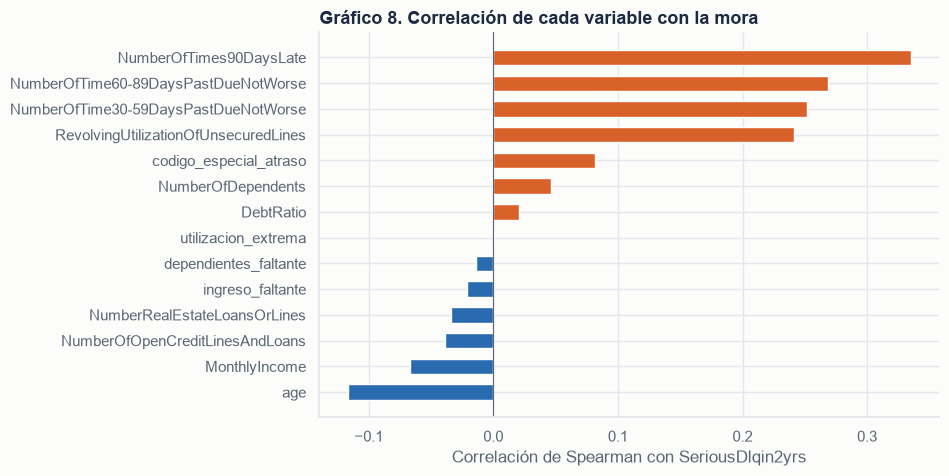

In [21]:
correlacion = (df_limpio[PREDICTORAS_MODELO + [OBJETIVO]]
               .corr(method="spearman")[OBJETIVO].drop(OBJETIVO).sort_values())
print(correlacion.round(3))

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(correlacion.index, correlacion.values,
        color=[NARANJA if v > 0 else AZUL for v in correlacion.values], height=0.6)
ax.axvline(0, color=TINTA_SECUNDARIA, linewidth=0.8)
ax.set_xlabel("Correlación de Spearman con SeriousDlqin2yrs")
ax.set_title("Gráfico 8. Correlación de cada variable con la mora")
guardar_figura(fig, "08_correlacion_objetivo")
plt.show()

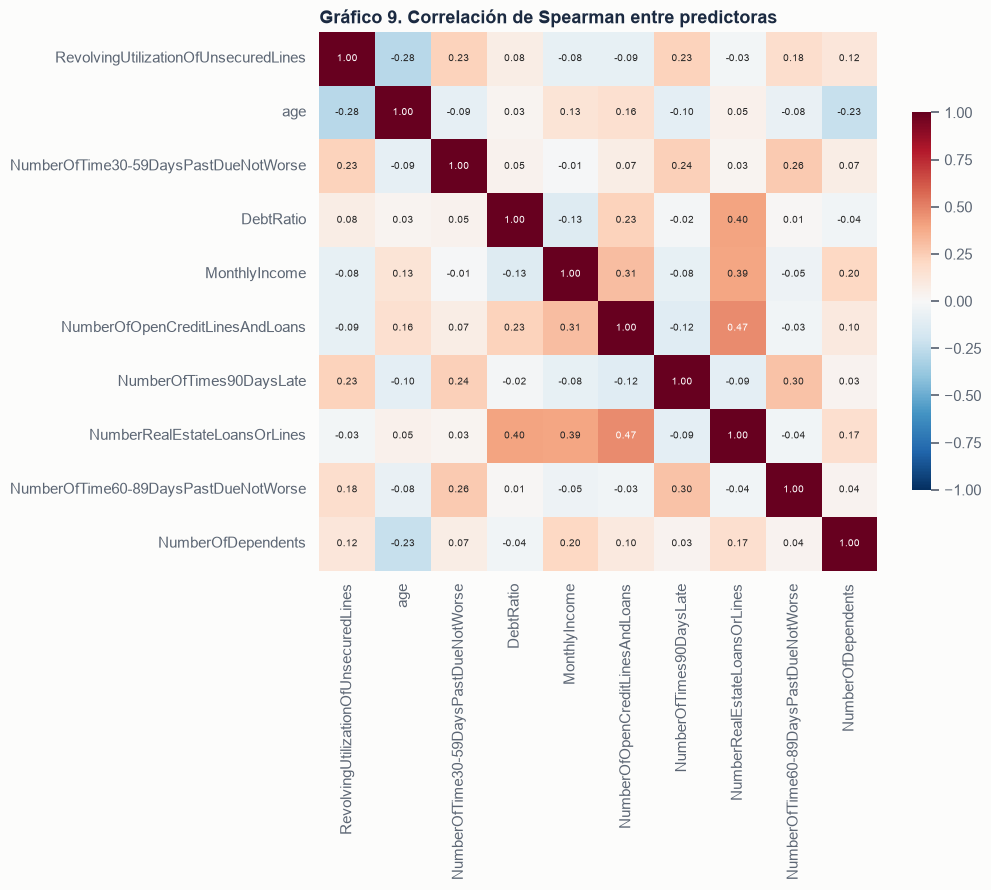

In [22]:
fig, ax = plt.subplots(figsize=(9, 7))
matriz = df_limpio[PREDICTORAS_ORIGINALES].corr(method="spearman")
sns.heatmap(matriz, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 7}, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Gráfico 9. Correlación de Spearman entre predictoras")
guardar_figura(fig, "09_correlacion_predictoras")
plt.show()

**Interpretación.** Se usa Spearman porque las variables son asimétricas y con extremos. Las
asociaciones positivas más fuertes con la mora son los atrasos de 90+ días (0,335), de 60-89 días
(0,268) y de 30-59 días (0,251), y la utilización del crédito (0,241). La edad (−0,117) y el ingreso
(−0,067) se asocian negativamente. Entre predictoras, las relaciones más fuertes son líneas de crédito
abiertas con préstamos inmobiliarios (0,47), ratio de deuda con préstamos inmobiliarios (0,40), ingreso
con préstamos inmobiliarios (0,39) y utilización con edad (−0,28). Las tres variables de atraso se
correlacionan moderadamente entre sí (0,24-0,30), así que aportan información parcialmente distinta y no
hay multicolinealidad severa.
Una correlación de rango no implica causalidad ni captura interacciones; el modelo lo evaluará mejor.

## 12. Conclusiones de negocio

1. **Mora de 6,68 %** (10 026 de 150 000): problema desbalanceado; accuracy no sirve como métrica principal.
2. **El historial de atrasos es la señal más fuerte.** Un atraso de 90+ días eleva la tasa de mora de
   4,63 % a 33,66 %; dos o más, a 55,20 %.
3. **La utilización del crédito rotativo discrimina mucho:** 2,22 % por debajo del 30 % de uso frente a
   39,61 % sobre el límite. Es una variable accionable para alertas tempranas.
4. **Los jóvenes concentran más riesgo:** 11,73 % entre 18 y 29 años frente a 3,10 % desde 60 años.
5. **Ingreso y dependientes** tienen una relación más débil pero consistente (más ingreso, menos mora;
   más dependientes, más mora).
6. **Calidad de datos:** 19,82 % sin ingreso, 269 clientes con códigos 96/98 (mora 54,65 %) y 241
   utilizaciones > 10 que se comportan como errores. Se tratan con nulos + indicadores, sin eliminar filas.

Estas conclusiones describen asociaciones en datos históricos y no permiten afirmar relaciones causales.

In [23]:
assert hashlib.sha256(RUTA_TRAINING.read_bytes()).hexdigest() == hash_inicial
print("El archivo cs-training.csv no fue modificado durante el análisis.")

El archivo cs-training.csv no fue modificado durante el análisis.
